# TP2 — Classification : quels clients vont résilier ? (Correction)

Cours associé : [TP2_Cours.md](TP2_Cours.md) · Pense-bête : [Pense_bete_Pandas.md](../Pense_bete_Pandas.md)

## Contexte

Un opérateur de télécommunications perd chaque mois une partie de ses abonnés : c'est l'**attrition** (en anglais *churn*). Retenir un client coûte beaucoup moins cher que d'en conquérir un nouveau : le service marketing veut donc repérer **à l'avance** les clients qui risquent de partir, pour leur proposer une offre adaptée.

Le fichier `data/telco_churn.csv` décrit environ 7 000 clients : leur contrat, leur ancienneté, leur facture, les services souscrits… et indique s'ils ont résilié leur abonnement (`Churn = Yes`).

**Objectif** : construire un modèle qui prédit si un client va résilier, et évaluer honnêtement ses performances.

## Déroulé

| Partie | Contenu |
|---|---|
| 1 | Exploration des données |
| 2 | Découpage train / test et baseline |
| 3 | Pipeline de préparation et régression logistique |
| 4 | Métriques d'évaluation |
| 5 | k-NN, arbre de décision et sur-apprentissage |
| 6 | Validation croisée et choix du modèle |
| 7 | *Facultatif* : approfondissements |

Les cellules marquées `# TODO` sont à compléter. Les cellules ✍️ attendent une réponse rédigée.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, classification_report,
                             ConfusionMatrixDisplay, RocCurveDisplay)

plt.rcParams["figure.figsize"] = (8, 5)
RANDOM_STATE = 42

## Partie 1 — Exploration des données

| Colonne | Signification |
|---|---|
| `customerID` | identifiant du client |
| `gender`, `SeniorCitizen`, `Partner`, `Dependents` | sexe, plus de 65 ans (1/0), en couple, personnes à charge |
| `tenure` | ancienneté, en mois |
| `PhoneService`, `MultipleLines` | téléphone, plusieurs lignes |
| `InternetService` | type d'accès : `DSL`, `Fiber optic` ou `No` |
| `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport` | options de sécurité, sauvegarde, protection, assistance |
| `StreamingTV`, `StreamingMovies` | options de streaming |
| `Contract` | type de contrat : au mois, un an ou deux ans |
| `PaperlessBilling`, `PaymentMethod` | facture dématérialisée, mode de paiement |
| `MonthlyCharges`, `TotalCharges` | facture mensuelle et total facturé depuis l'abonnement ($) |
| `Churn` | le client a-t-il résilié ? `Yes` ou `No` (**cible**) |

**1.1** Chargez les données dans `df`, affichez les dimensions, les premières lignes et les types des colonnes (`dtypes`). Une colonne numérique a-t-elle un type surprenant ?

In [2]:
# TODO : chargement, dimensions, types
df = pd.read_csv("data/telco_churn.csv")
print(df.shape)
print(df.dtypes)
df.head()

(7043, 21)
customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


**1.2** La colonne `TotalCharges` est stockée comme du texte. Convertissez-la en nombre avec `pd.to_numeric(..., errors="coerce")` : les valeurs impossibles à convertir deviennent `NaN`. Combien y en a-t-il ? Regardez l'ancienneté (`tenure`) de ces clients : pourquoi n'ont-ils pas de montant total ?

In [3]:
# TODO : conversion de TotalCharges et étude des valeurs manquantes
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("valeurs manquantes :", df["TotalCharges"].isna().sum())
df.loc[df["TotalCharges"].isna(), ["tenure", "MonthlyCharges", "TotalCharges"]]

valeurs manquantes : 11


,tenure,MonthlyCharges,TotalCharges
488,0,52.55,NaN
753,0,20.25,NaN
936,0,80.85,NaN
1082,0,25.75,NaN
1340,0,56.05,NaN
3331,0,19.85,NaN
3826,0,25.35,NaN
4380,0,20.00,NaN
5218,0,19.70,NaN
6670,0,73.35,NaN


✅ **Éléments de réponse**

- `TotalCharges` est de type texte alors qu'elle contient des montants : quelques lignes contiennent une chaîne vide `" "`, ce qui empêche pandas de la lire comme un nombre. C'est un piège très fréquent dans les données réelles : il faut toujours vérifier les types.
- Après conversion, **11 clients** ont un total manquant. Ils ont tous une ancienneté de **0 mois** : ils viennent de s'abonner et n'ont encore reçu aucune facture. La valeur manquante a donc une explication logique ; on pourrait la remplacer par 0, mais on laissera le pipeline l'imputer (partie 3).

**1.3** Quel est le taux de résiliation global ? Calculez ensuite le taux de résiliation selon le type de contrat (`Contract`), le type d'accès internet (`InternetService`) et le mode de paiement (`PaymentMethod`).

*Astuce : créez d'abord une colonne numérique `churn` valant 1 si `Churn == "Yes"`, 0 sinon ; son taux moyen est alors le taux de résiliation.*

In [4]:
# TODO : taux de résiliation global et par groupe
df["churn"] = (df["Churn"] == "Yes").astype(int)
print("taux global :", df["churn"].mean().round(3))
for col in ["Contract", "InternetService", "PaymentMethod"]:
    print(df.groupby(col)["churn"].mean().round(3).sort_values(ascending=False), "\n")

taux global : 0.265
Contract
Month-to-month    0.427
One year          0.113
Two year          0.028
Name: churn, dtype: float64 

InternetService
Fiber optic    0.419
DSL            0.190
No             0.074
Name: churn, dtype: float64 

PaymentMethod
Electronic check             0.453
Mailed check                 0.191
Bank transfer (automatic)    0.167
Credit card (automatic)      0.152
Name: churn, dtype: float64 



**1.4** Comparez l'ancienneté (`tenure`) des clients qui partent et de ceux qui restent (deux histogrammes superposés), puis leur facture mensuelle moyenne.

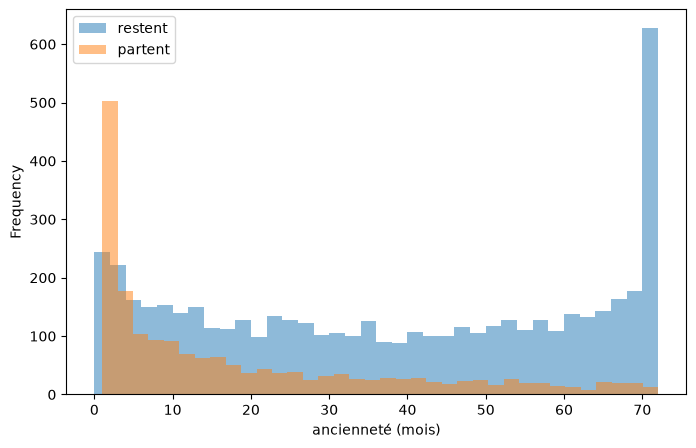

,tenure,MonthlyCharges
churn,,
0,37.6,61.3
1,18.0,74.4


In [5]:
# TODO : ancienneté et facture selon la résiliation
df.loc[df["churn"] == 0, "tenure"].plot.hist(bins=36, alpha=0.5, label="restent")
df.loc[df["churn"] == 1, "tenure"].plot.hist(bins=36, alpha=0.5, label="partent")
plt.xlabel("ancienneté (mois)")
plt.legend()
plt.show()
df.groupby("churn")[["tenure", "MonthlyCharges"]].mean().round(1)

✅ **Éléments de réponse**

- Environ **26,5 %** des clients ont résilié : les classes sont **déséquilibrées** (environ 3 clients sur 4 restent).
- Le **type de contrat** est très discriminant : 43 % de départs pour les contrats au mois, 11 % pour un an, moins de 3 % pour deux ans.
- Les clients en **fibre optique** partent beaucoup plus (42 %) que ceux en DSL (19 %), et ceux qui paient par **chèque électronique** aussi (45 %).
- Les clients qui partent sont **récents** (18 mois d'ancienneté en moyenne, contre 38 pour ceux qui restent) et paient **plus cher** (74 $ par mois contre 61 $). L'histogramme montre un pic de départs dans les premiers mois.

**1.5** Quelle colonne faut-il exclure des variables explicatives ? Pourquoi ?

✅ **Éléments de réponse**

- `customerID` : c'est un identifiant, unique pour chaque client. Il ne contient aucune information sur le comportement ; le garder permettrait seulement au modèle d'apprendre par cœur.
- Bien sûr, `Churn` et `churn` sont la cible : elles ne doivent pas figurer parmi les variables explicatives, sinon le modèle « verrait la réponse ».

## Partie 2 — Découpage train / test et baseline

**2.1** Construisez `X` (toutes les colonnes sauf `customerID`, `Churn` et `churn`) et `y` (`churn`), puis découpez en 80 % entraînement / 20 % test, de façon **stratifiée**, avec `random_state=RANDOM_STATE`. Vérifiez que le taux de résiliation est le même dans les deux jeux.

In [6]:
# TODO : X, y et découpage stratifié
X = df.drop(columns=["customerID", "Churn", "churn"])
y = df["churn"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(X_train.shape, X_test.shape)
print(round(y_train.mean(), 3), round(y_test.mean(), 3))

(5634, 19) (1409, 19)
0.265 0.265


**2.2** Entraînez un `DummyClassifier(strategy="most_frequent")` et calculez son exactitude sur le jeu de test. Que prédit-il ? Ce modèle est-il utile au service marketing ?

In [7]:
# TODO : baseline
baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
print("exactitude baseline :", round(baseline.score(X_test, y_test), 3))

exactitude baseline : 0.735


✅ **Éléments de réponse**

Le `DummyClassifier` prédit que **personne ne part** et obtient environ **73 %** d'exactitude sans rien apprendre. C'est le plancher à battre. Mais il est totalement inutile au métier : il ne repère aucun client sur le départ. On voit déjà que l'exactitude seule ne suffira pas à juger un modèle (partie 4).

## Partie 3 — Pipeline de préparation et régression logistique

**3.1** Construisez un `ColumnTransformer` nommé `preprocess` qui :

- pour les colonnes numériques `tenure`, `MonthlyCharges`, `TotalCharges`, `SeniorCitizen` : impute par la **médiane** puis **standardise** ;
- pour toutes les autres colonnes (catégorielles) : impute par la **modalité la plus fréquente** puis applique un **one-hot encoding** (`handle_unknown="ignore"`).

*Astuce : `X.select_dtypes(exclude="number").columns` donne la liste des colonnes non numériques.*

In [8]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen"]
# TODO : liste des colonnes catégorielles et ColumnTransformer
cat_cols = X.select_dtypes(exclude="number").columns.tolist()
print(len(cat_cols), "colonnes catégorielles :", cat_cols)
preprocess = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num_cols),
    ("cat", make_pipeline(SimpleImputer(strategy="most_frequent"),
                          OneHotEncoder(handle_unknown="ignore")), cat_cols),
])
preprocess

15 colonnes catégorielles : ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

**3.2** Créez un `Pipeline` `logreg` qui enchaîne `preprocess` et une `LogisticRegression(max_iter=1000)`. Entraînez-le et affichez l'exactitude sur le jeu d'entraînement et sur le jeu de test.

In [9]:
# TODO : pipeline régression logistique
logreg = Pipeline([("prep", preprocess), ("clf", LogisticRegression(max_iter=1000))])
logreg.fit(X_train, y_train)
print("train :", round(logreg.score(X_train, y_train), 3))
print("test  :", round(logreg.score(X_test, y_test), 3))

train : 0.806
test  : 0.806


**3.3** Affichez les 8 coefficients les plus positifs et les 8 plus négatifs de la régression logistique, en face des noms de variables. Quels facteurs augmentent le risque de départ ? Lesquels le diminuent ? Est-ce cohérent avec la partie 1 ?

*Indice : `logreg.named_steps["clf"].coef_[0]` et `logreg.named_steps["prep"].get_feature_names_out()`.*

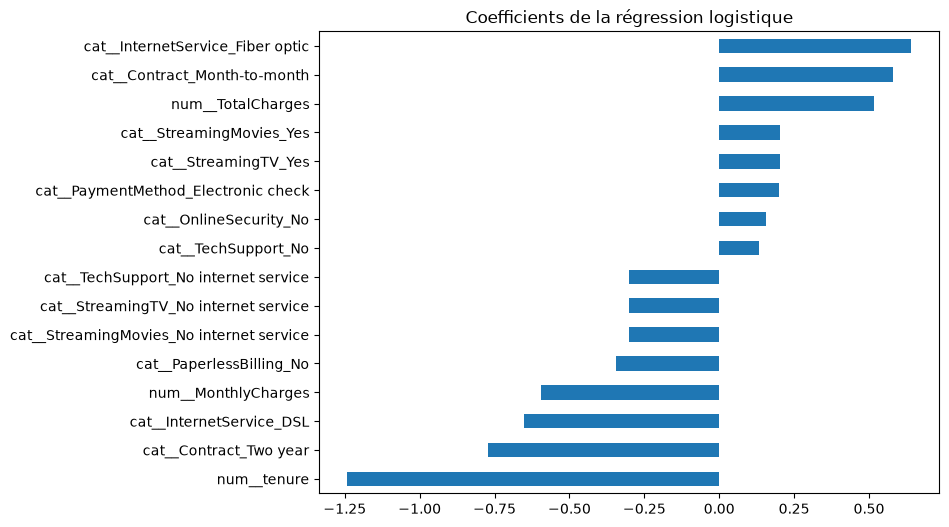

num__tenure                                -1.24
cat__Contract_Two year                     -0.77
cat__InternetService_DSL                   -0.65
num__MonthlyCharges                        -0.60
cat__PaperlessBilling_No                   -0.34
cat__StreamingMovies_No internet service   -0.30
cat__StreamingTV_No internet service       -0.30
cat__TechSupport_No internet service       -0.30
cat__TechSupport_No                         0.13
cat__OnlineSecurity_No                      0.16
cat__PaymentMethod_Electronic check         0.20
cat__StreamingTV_Yes                        0.20
cat__StreamingMovies_Yes                    0.20
num__TotalCharges                           0.52
cat__Contract_Month-to-month                0.58
cat__InternetService_Fiber optic            0.64
dtype: float64

In [10]:
# TODO : coefficients
coefs = pd.Series(logreg.named_steps["clf"].coef_[0],
                  index=logreg.named_steps["prep"].get_feature_names_out()).sort_values()
pd.concat([coefs.head(8), coefs.tail(8)]).plot.barh(figsize=(8, 6))
plt.title("Coefficients de la régression logistique")
plt.show()
pd.concat([coefs.head(8), coefs.tail(8)]).round(2)

✅ **Éléments de réponse**

- Le modèle atteint environ **81 %** d'exactitude, sur l'entraînement comme sur le test, au-dessus de la baseline (73 %) : pas de sur-apprentissage.
- Les coefficients **positifs** (qui augmentent le risque de départ) concernent surtout la **fibre optique** et le contrat **au mois** ; les plus **négatifs**, l'**ancienneté** (`tenure`, le plus fort de tous), le contrat de **deux ans** et l'accès DSL. C'est cohérent avec l'exploration.
- ⚠️ `MonthlyCharges` a un coefficient négatif alors que les clients qui partent paient plus cher ! C'est parce que `tenure`, `MonthlyCharges` et `TotalCharges` sont très liées (le total ≈ ancienneté × facture mensuelle) : leurs coefficients se compensent et ne doivent pas être interprétés isolément.

## Partie 4 — Métriques d'évaluation

**4.1** Affichez la matrice de confusion de `logreg` sur le jeu de test (`ConfusionMatrixDisplay.from_estimator`) et le `classification_report`. Parmi les clients qui sont vraiment partis, combien le modèle en a-t-il « ratés » ? Traduisez la précision et le rappel de la classe « part » en une phrase chacun pour le service marketing.

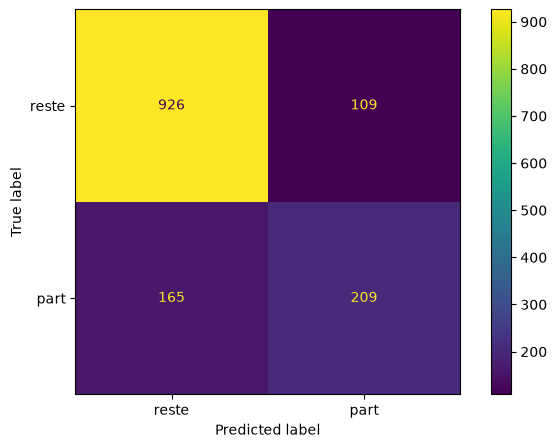

              precision    recall  f1-score   support

       reste       0.85      0.89      0.87      1035
        part       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



In [11]:
# TODO : matrice de confusion et rapport
ConfusionMatrixDisplay.from_estimator(logreg, X_test, y_test, display_labels=["reste", "part"])
plt.show()
y_pred = logreg.predict(X_test)
print(classification_report(y_test, y_pred, target_names=["reste", "part"]))

**4.2** Tracez la courbe ROC et calculez l'AUC. Puis, en utilisant `predict_proba`, calculez précision et rappel pour des seuils de décision de 0,3, 0,5 et 0,7. Quel seuil choisiriez-vous si une offre de fidélité coûte peu et qu'un client perdu coûte cher ?

AUC : 0.842


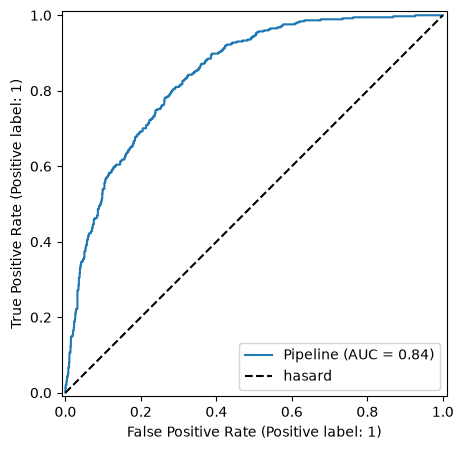

seuil 0.3 : précision = 0.52, rappel = 0.75
seuil 0.5 : précision = 0.66, rappel = 0.56
seuil 0.7 : précision = 0.74, rappel = 0.18


In [12]:
# TODO : ROC, AUC et effet du seuil
proba = logreg.predict_proba(X_test)[:, 1]
print("AUC :", round(roc_auc_score(y_test, proba), 3))
RocCurveDisplay.from_estimator(logreg, X_test, y_test)
plt.plot([0, 1], [0, 1], "k--", label="hasard")
plt.legend()
plt.show()

for seuil in [0.3, 0.5, 0.7]:
    pred = (proba >= seuil).astype(int)
    print(f"seuil {seuil} : précision = {precision_score(y_test, pred):.2f}, rappel = {recall_score(y_test, pred):.2f}")

✅ **Éléments de réponse**

- Le modèle ne repère qu'un peu plus de la moitié des clients qui partent : son **rappel** sur la classe « part » (0,56) est nettement plus faible que sa **précision** (0,66). Il « rate » 165 des 374 clients partis du jeu de test.
- Pour le marketing : la **précision** est la part des clients contactés qui allaient vraiment partir (les autres reçoivent une offre inutile) ; le **rappel** est la part des départs que l'on a su anticiper (les autres partent sans qu'on ait rien tenté).
- L'AUC d'environ **0,84** indique un bon pouvoir de classement.
- **Baisser le seuil** à 0,3 fait monter le rappel à 0,75 (trois départs sur quatre repérés), au prix d'une précision de 0,52 ; **le monter** à 0,7 donne une précision de 0,74 mais un rappel de 0,18. Si une offre coûte peu et qu'un client perdu coûte cher, on **baisse le seuil** : mieux vaut contacter trop de clients que d'en laisser partir.

## Partie 5 — k-NN, arbre de décision et sur-apprentissage

**5.1** Créez un pipeline `knn` (même `preprocess` + `KNeighborsClassifier(n_neighbors=5)`) et un pipeline `arbre` (`preprocess` + `DecisionTreeClassifier(random_state=RANDOM_STATE)` sans limite de profondeur). Pour chacun, affichez l'exactitude en entraînement et en test.

*Astuce : réutiliser le même objet `preprocess` dans plusieurs pipelines pose problème (il serait partagé). Utilisez `sklearn.base.clone(preprocess)`.*

In [13]:
from sklearn.base import clone

# TODO : k-NN et arbre non contraint
knn = Pipeline([("prep", clone(preprocess)), ("clf", KNeighborsClassifier(n_neighbors=5))])
arbre = Pipeline([("prep", clone(preprocess)), ("clf", DecisionTreeClassifier(random_state=RANDOM_STATE))])

for nom, modele in [("k-NN", knn), ("arbre", arbre)]:
    modele.fit(X_train, y_train)
    print(f"{nom:6s} train = {modele.score(X_train, y_train):.3f}  test = {modele.score(X_test, y_test):.3f}")

k-NN   train = 0.837  test = 0.764
arbre  train = 0.998  test = 0.727


**5.2** Faites varier la profondeur maximale de l'arbre (`max_depth` de 1 à 15) et tracez l'exactitude en entraînement et en test en fonction de la profondeur. Identifiez les zones de sous-apprentissage et de sur-apprentissage.

*Astuce : `arbre.set_params(clf__max_depth=d)` modifie un hyperparamètre d'une étape du pipeline.*

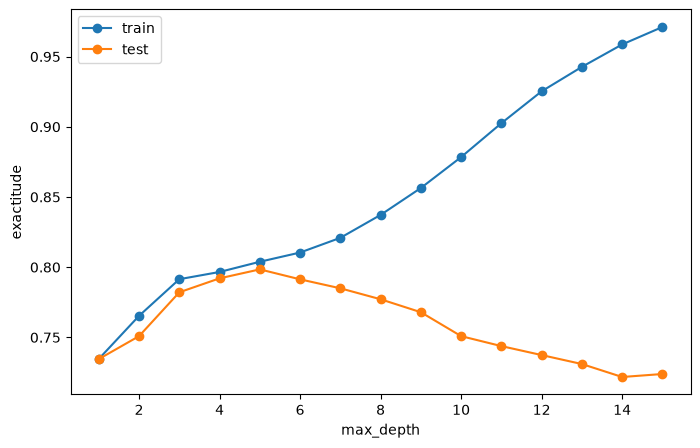

In [14]:
# TODO : courbe de complexité de l'arbre
profondeurs = range(1, 16)
scores_train, scores_test = [], []
for d in profondeurs:
    arbre.set_params(clf__max_depth=d).fit(X_train, y_train)
    scores_train.append(arbre.score(X_train, y_train))
    scores_test.append(arbre.score(X_test, y_test))

plt.plot(profondeurs, scores_train, marker="o", label="train")
plt.plot(profondeurs, scores_test, marker="o", label="test")
plt.xlabel("max_depth")
plt.ylabel("exactitude")
plt.legend()
plt.show()

✅ **Éléments de réponse**

- L'arbre sans limite de profondeur atteint **99,8 %** en entraînement mais seulement **73 %** en test, **moins que la baseline** : il a appris le jeu d'entraînement par cœur, c'est du **sur-apprentissage**. Le k-NN présente un écart plus modéré (84 % / 76 %).
- Sur la courbe : avec une profondeur de 1 ou 2, les deux scores sont bas et proches (**sous-apprentissage** ; à la profondeur 1, l'arbre ne fait pas mieux que la baseline). Le score de test culmine vers une profondeur de 5 (≈ 80 %), puis baisse régulièrement alors que le score d'entraînement monte vers 100 % : l'arbre apprend du bruit (**sur-apprentissage**).
- ⚠️ Choisir la profondeur en regardant le jeu de test est une mauvaise pratique, que la partie 6 corrige.

## Partie 6 — Validation croisée et choix du modèle

**6.1** Évaluez les trois pipelines (`logreg`, `knn` et `arbre` avec `max_depth=None`) par **validation croisée à 5 plis sur le jeu d'entraînement** (`cross_val_score`), en utilisant cette fois l'**AUC** comme métrique (`scoring="roc_auc"`), mieux adaptée aux classes déséquilibrées. Affichez la moyenne et l'écart-type pour chacun.

In [15]:
# TODO : validation croisée des trois modèles
arbre.set_params(clf__max_depth=None)
auc_cv = {}
for nom, modele in [("logreg", logreg), ("k-NN", knn), ("arbre", arbre)]:
    scores = cross_val_score(modele, X_train, y_train, cv=5, scoring="roc_auc")
    auc_cv[nom] = scores.mean()
    print(f"{nom:7s} AUC = {scores.mean():.3f} ± {scores.std():.3f}")

logreg  AUC = 0.846 ± 0.014
k-NN    AUC = 0.781 ± 0.011


arbre   AUC = 0.643 ± 0.009


**6.2** Utilisez `GridSearchCV` (`scoring="roc_auc"`) pour régler simultanément `max_depth` (2 à 10) et `min_samples_leaf` (1, 10, 25, 50) de l'arbre, en validation croisée à 5 plis. Affichez les meilleurs hyperparamètres et le score correspondant.

In [16]:
# TODO : recherche d'hyperparamètres pour l'arbre
grille_arbre = {"clf__max_depth": range(2, 11), "clf__min_samples_leaf": [1, 10, 25, 50]}
gs_arbre = GridSearchCV(arbre, grille_arbre, cv=5, scoring="roc_auc")
gs_arbre.fit(X_train, y_train)
print(gs_arbre.best_params_, round(gs_arbre.best_score_, 3))

{'clf__max_depth': 6, 'clf__min_samples_leaf': 50} 0.831


**6.3** Choisissez **un** modèle final à partir des scores de validation croisée (régression logistique, k-NN à 5 voisins, arbre réglé), puis évaluez-le **une seule fois** sur le jeu de test (AUC, précision et rappel). Concluez pour le service marketing.

In [17]:
# TODO : évaluation finale
candidats = {"logreg": auc_cv["logreg"], "k-NN": auc_cv["k-NN"], "arbre réglé": gs_arbre.best_score_}
print({k: round(float(v), 3) for k, v in candidats.items()})

modeles = {"logreg": logreg, "k-NN": knn, "arbre réglé": gs_arbre.best_estimator_}
nom_final = max(candidats, key=candidats.get)
final = modeles[nom_final].fit(X_train, y_train)
print("modèle retenu :", nom_final)
y_pred_final = final.predict(X_test)
print("AUC       :", round(roc_auc_score(y_test, final.predict_proba(X_test)[:, 1]), 3))
print("précision :", round(precision_score(y_test, y_pred_final), 3))
print("rappel    :", round(recall_score(y_test, y_pred_final), 3))

{'logreg': 0.846, 'k-NN': 0.781, 'arbre réglé': 0.831}
modèle retenu : logreg
AUC       : 0.842
précision : 0.657
rappel    : 0.559


✅ **Éléments de réponse**

- En validation croisée, l'arbre non contraint est nettement le moins bon (AUC ≈ 0,64) et le k-NN à 5 voisins reste en retrait (0,78). Une fois réglé (profondeur 6 et au moins 50 clients par feuille), l'arbre atteint 0,83, mais la **régression logistique reste la meilleure** (0,85) : elle est retenue.
- Le score obtenu sur le test (AUC 0,84) est cohérent avec la validation croisée : l'estimation est honnête parce que le test n'a servi **qu'une seule fois**, à la fin.
- Pour le marketing : le modèle classe bien les clients selon leur risque de départ. Avec le seuil par défaut de 50 %, il ne repère qu'un peu plus de la moitié des départs ; il faudra **baisser le seuil** selon le budget de l'opération de fidélisation (voir le bonus).
- La régression logistique a un atout supplémentaire : ses coefficients s'expliquent au métier (contrat au mois, fibre, ancienneté).

## Partie 7 — *Facultatif* : approfondissements

*À faire si vous avez terminé le reste. Les questions sont indépendantes les unes des autres.*

**7.1** Pour comprendre ce que fait `preprocess`, appliquez-le au jeu d'entraînement (`fit_transform`) : combien de colonnes obtient-on ? Affichez le résultat sous forme de DataFrame avec les noms de colonnes produits (`get_feature_names_out()`).

In [18]:
# TODO : observer la sortie du préprocesseur
X_train_prep = preprocess.fit_transform(X_train)
print(X_train_prep.shape)
pd.DataFrame(X_train_prep, columns=preprocess.get_feature_names_out()).head()

(5634, 45)


,num__tenure,num__MonthlyCharges,num__TotalCharges,num__SeniorCitizen,cat__gender_Female,cat__gender_Male,cat__Partner_No,cat__Partner_Yes,cat__Dependents_No,cat__Dependents_Yes,...,cat__StreamingMovies_Yes,cat__Contract_Month-to-month,cat__Contract_One year,cat__Contract_Two year,cat__PaperlessBilling_No,cat__PaperlessBilling_Yes,cat__PaymentMethod_Bank transfer (automatic),cat__PaymentMethod_Credit card (automatic),cat__PaymentMethod_Electronic check,cat__PaymentMethod_Mailed check
0,0.102371,-0.521976,-0.263290,-0.441773,0.0,1.0,1.0,0.0,1.0,0.0,...,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
1,-0.711743,0.337478,-0.504815,-0.441773,0.0,1.0,0.0,1.0,0.0,1.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
2,-0.793155,-0.809013,-0.751214,-0.441773,0.0,1.0,0.0,1.0,0.0,1.0,...,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0
3,-0.263980,0.284384,-0.173700,-0.441773,1.0,0.0,0.0,1.0,1.0,0.0,...,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0
4,-1.281624,-0.676279,-0.990851,-0.441773,0.0,1.0,0.0,1.0,0.0,1.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0


✅ **Éléments de réponse**

Le préprocesseur transforme les 19 variables en **45 colonnes** : chaque variable catégorielle devient une colonne par modalité (par exemple `Contract_Month-to-month`, `Contract_One year`, `Contract_Two year`).

**7.2** Recalculez **à la main** (à partir des quatre cases de la matrice de confusion de `logreg`) la précision et le rappel de la classe « part », puis vérifiez avec `precision_score` et `recall_score`.

In [19]:
# TODO : précision et rappel à la main
y_pred = logreg.predict(X_test)
vp = ((y_pred == 1) & (y_test == 1)).sum()
fp = ((y_pred == 1) & (y_test == 0)).sum()
fn = ((y_pred == 0) & (y_test == 1)).sum()
print("précision :", round(vp / (vp + fp), 3), "=", round(precision_score(y_test, y_pred), 3))
print("rappel    :", round(vp / (vp + fn), 3), "=", round(recall_score(y_test, y_pred), 3))

précision : 0.657 = 0.657
rappel    : 0.559 = 0.559


**7.3** Entraînez un arbre de profondeur 3 et affichez-le avec `plot_tree` (paramètres utiles : `feature_names`, `class_names`, `filled=True`). Quelles sont les premières questions posées par l'arbre ?

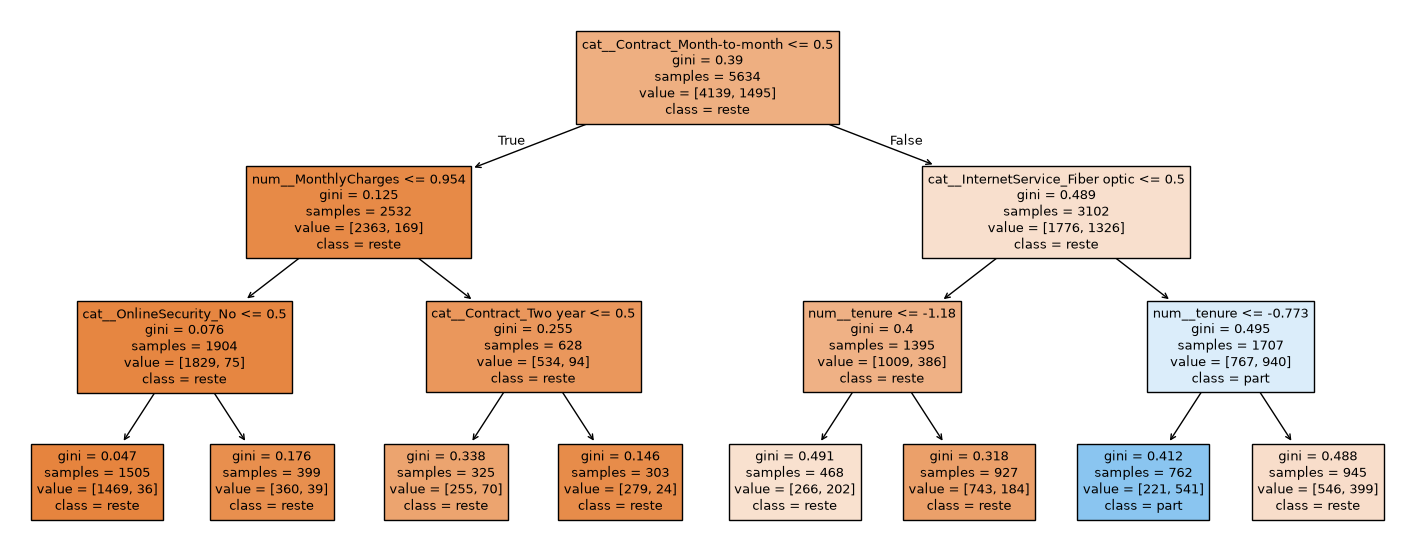

In [20]:
# TODO : visualiser un arbre peu profond
arbre3 = Pipeline([("prep", clone(preprocess)),
                   ("clf", DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE))])
arbre3.fit(X_train, y_train)
plt.figure(figsize=(18, 7))
plot_tree(arbre3.named_steps["clf"],
          feature_names=arbre3.named_steps["prep"].get_feature_names_out(),
          class_names=["reste", "part"], filled=True, fontsize=9)
plt.show()

✅ **Éléments de réponse**

La première question porte sur le **type de contrat** (au mois ou non), puis viennent le **type d'accès internet** (fibre ou non) et l'**ancienneté**. L'arbre retrouve seul le portrait-type du client à risque : un contrat sans engagement, un abonnement récent et la fibre optique.

**7.4** Réglez le k-NN avec `GridSearchCV` (`scoring="roc_auc"`, 5 plis) pour `n_neighbors` de 5 à 100 (par pas de 5). Rattrape-t-il la régression logistique ?

In [21]:
# TODO : recherche d'hyperparamètres pour le k-NN
gs_knn = GridSearchCV(knn, {"clf__n_neighbors": range(5, 101, 5)}, cv=5, scoring="roc_auc")
gs_knn.fit(X_train, y_train)
print(gs_knn.best_params_, round(gs_knn.best_score_, 3))

{'clf__n_neighbors': 95} 0.836


✅ **Éléments de réponse**

Avec 95 voisins, le k-NN atteint une AUC de 0,84 en validation croisée, bien mieux qu'avec 5 voisins (0,78) : un grand nombre de voisins lisse la décision. Il reste malgré tout légèrement en dessous de la régression logistique (0,85).

## Pour aller plus loin (bonus)

**Choisir le seuil selon les coûts.** Supposons qu'une offre de fidélité coûte **50 $** par client contacté, et qu'un client perdu coûte **500 $** (le chiffre d'affaires qu'il aurait rapporté). On suppose aussi que l'offre suffit à retenir un client qui allait partir.

1. Pour des seuils de 0,05 à 0,95, calculez le coût total sur le jeu de test : 50 $ par client contacté (prédit « part ») + 500 $ par départ non repéré (faux négatif).
2. Tracez le coût en fonction du seuil. Quel seuil minimise le coût ? Combien économise-t-on par rapport au seuil de 0,5, et par rapport à « ne rien faire » ?

*Remarque : en toute rigueur, le seuil devrait être choisi sur des données de validation, pas sur le jeu de test.*

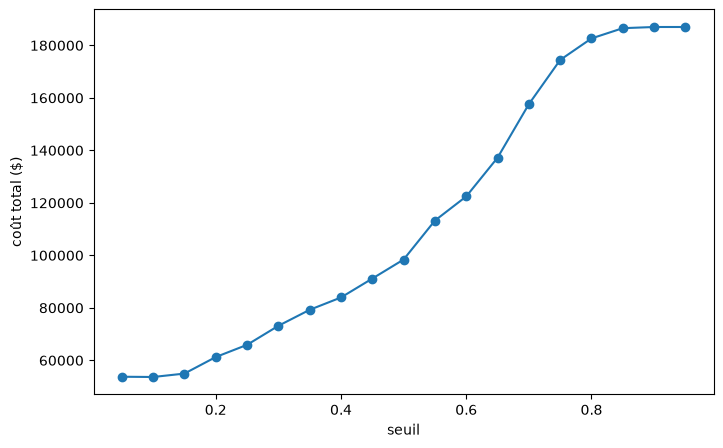

seuil optimal : 0.1 | coût : 53650 $
coût au seuil 0,5 : 98400 $ | ne rien faire : 187000 $


In [22]:
# Bonus : seuil qui minimise le coût
COUT_OFFRE, COUT_DEPART = 50, 500
proba = logreg.predict_proba(X_test)[:, 1]
seuils = np.round(np.arange(0.05, 0.96, 0.05), 2)
couts = []
for s in seuils:
    contactes = proba >= s
    rates = (~contactes) & (y_test.values == 1)
    couts.append(COUT_OFFRE * contactes.sum() + COUT_DEPART * rates.sum())
couts = pd.Series(couts, index=seuils)
couts.plot(marker="o")
plt.xlabel("seuil")
plt.ylabel("coût total ($)")
plt.show()
print("seuil optimal :", couts.idxmin(), "| coût :", couts.min(), "$")
print("coût au seuil 0,5 :", couts.loc[0.5], "$ | ne rien faire :", COUT_DEPART * y_test.sum(), "$")

✅ **Éléments de réponse**

Avec ces coûts, le seuil optimal est très bas (environ **0,1**) : il vaut mieux contacter beaucoup de clients, car une offre coûte dix fois moins cher qu'un départ. Le coût total tombe à environ **54 000 $**, contre 98 000 $ avec le seuil par défaut de 0,5 et **187 000 $** si l'on ne fait rien. Le bon seuil ne se déduit pas du modèle, mais des **coûts métier**.